In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/eergy-efficiency-dataset/ENB2012_data.csv


# Import Libraries

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Data load and visualization

In [3]:
df = pd.read_csv("/kaggle/input/eergy-efficiency-dataset/ENB2012_data.csv")

In [4]:
df.head()

,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X1      768 non-null    float64
 1   X2      768 non-null    float64
 2   X3      768 non-null    float64
 3   X4      768 non-null    float64
 4   X5      768 non-null    float64
 5   X6      768 non-null    int64  
 6   X7      768 non-null    float64
 7   X8      768 non-null    int64  
 8   Y1      768 non-null    float64
 9   Y2      768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB


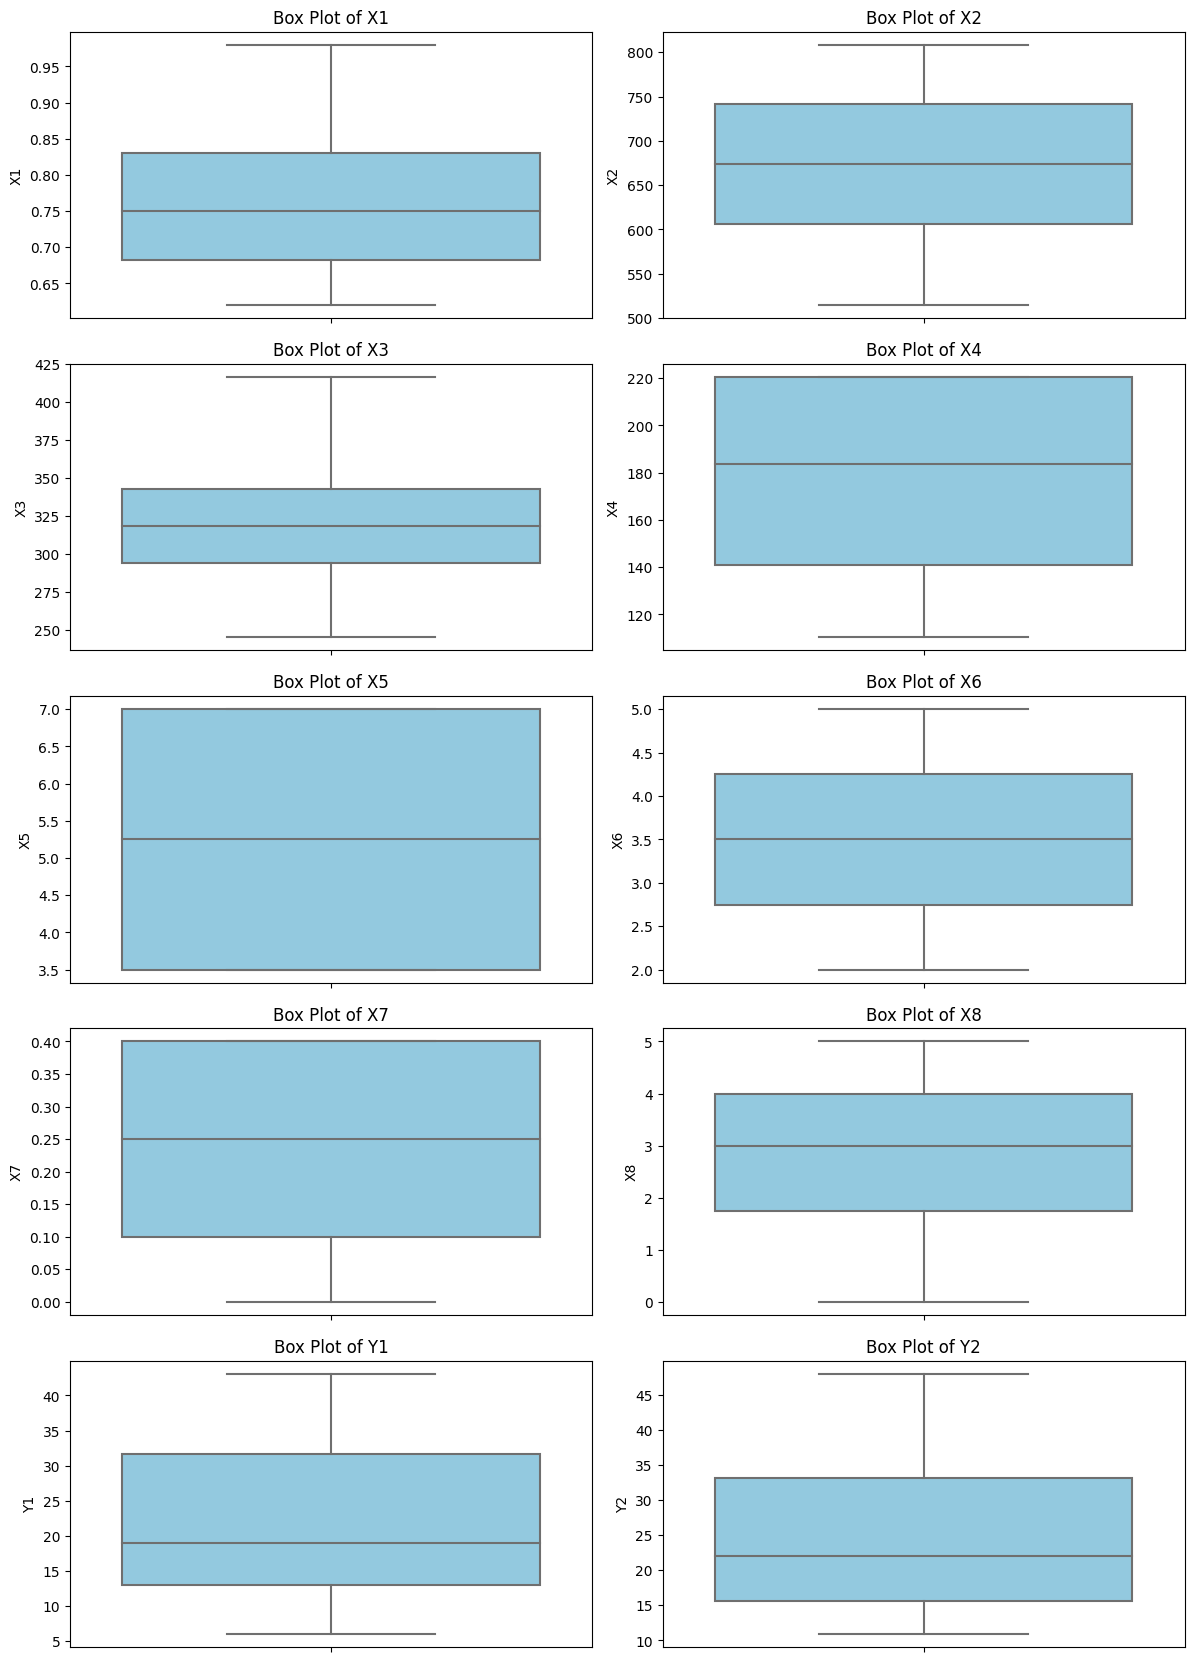

In [6]:
num_columns = df.columns
plt.figure(figsize=(12, 20))

for i, col in enumerate(num_columns, 1):
    plt.subplot(len(num_columns) // 2 + 1, 2, i) 
    sns.boxplot(y=df[col], color="skyblue")
    plt.title(f"Box Plot of {col}")
plt.tight_layout()
plt.show()

Text(0, 0.5, 'Values')

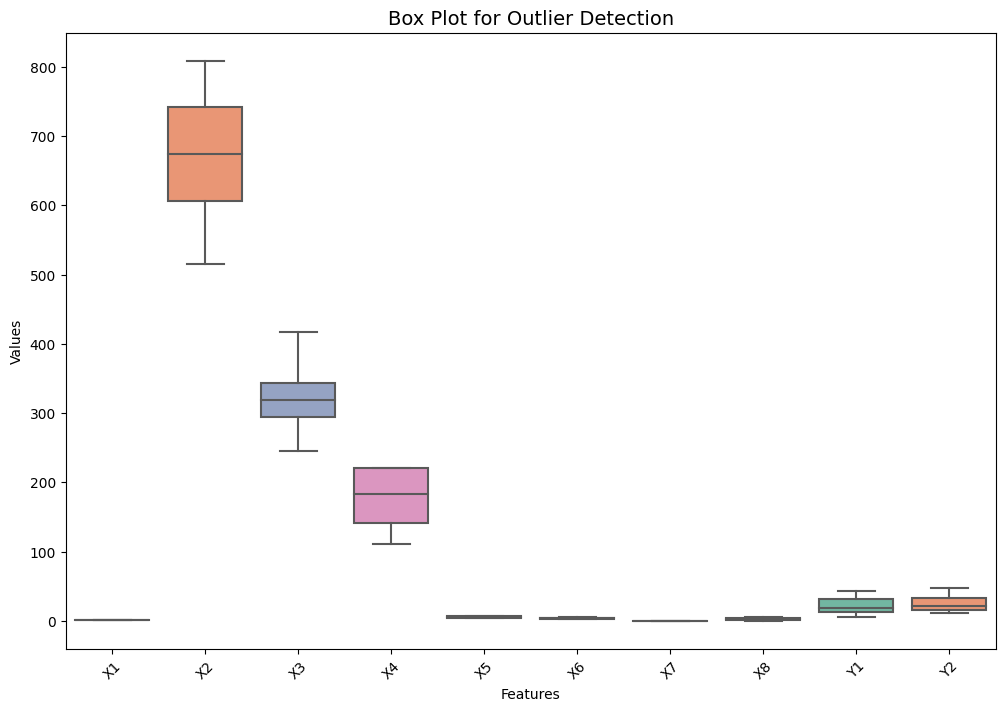

In [7]:
plt.figure(figsize=(12, 8))
sns.boxplot(data=df, orient="v", palette="Set2")
plt.title("Box Plot for Outlier Detection", fontsize=14)
plt.xticks(rotation=45)
plt.xlabel("Features")
plt.ylabel("Values")

# Using LinearRegression

In [8]:
X = df.iloc[:, :-2]  
Y1 = df["Y1"] 
Y2 = df["Y2"] 

X_train, X_test, Y1_train, Y1_test = train_test_split(X, Y1, test_size=0.2, random_state=42)
X_train, X_test, Y2_train, Y2_test = train_test_split(X, Y2, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_model_Y1 = LinearRegression()
lr_model_Y2 = LinearRegression()

lr_model_Y1.fit(X_train_scaled, Y1_train)
lr_model_Y2.fit(X_train_scaled, Y2_train)

Y1_lr_pred = lr_model_Y1.predict(X_test_scaled)
Y2_lr_pred = lr_model_Y2.predict(X_test_scaled)

rmse_Y1_lr = mean_squared_error(Y1_test, Y1_lr_pred, squared=False)
r2_Y1_lr = r2_score(Y1_test, Y1_lr_pred)

rmse_Y2_lr = mean_squared_error(Y2_test, Y2_lr_pred, squared=False)
r2_Y2_lr = r2_score(Y2_test, Y2_lr_pred)
print(f"Linear Regression - Heating Load (Y1): RMSE = {rmse_Y1_lr:.2f}, R² = {r2_Y1_lr:.4f}")
print(f"Linear Regression - Cooling Load (Y2): RMSE = {rmse_Y2_lr:.2f}, R² = {r2_Y2_lr:.4f}")

Linear Regression - Heating Load (Y1): RMSE = 3.03, R² = 0.9122
Linear Regression - Cooling Load (Y2): RMSE = 3.15, R² = 0.8932


# Using Random Forest Regressor 

In [9]:
X = df.iloc[:, :-2]  
Y1 = df["Y1"]  
Y2 = df["Y2"]  

X_train, X_test, Y1_train, Y1_test = train_test_split(X, Y1, test_size=0.2, random_state=42)
X_train, X_test, Y2_train, Y2_test = train_test_split(X, Y2, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
rf_model_Y1 = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model_Y2 = RandomForestRegressor(n_estimators=100, random_state=42)

rf_model_Y1.fit(X_train_scaled, Y1_train)
rf_model_Y2.fit(X_train_scaled, Y2_train)

Y1_rf_pred = rf_model_Y1.predict(X_test_scaled)
Y2_rf_pred = rf_model_Y2.predict(X_test_scaled)
rmse_Y1_rf = mean_squared_error(Y1_test, Y1_rf_pred, squared=False)
r2_Y1_rf = r2_score(Y1_test, Y1_rf_pred)

rmse_Y2_rf = mean_squared_error(Y2_test, Y2_rf_pred, squared=False)
r2_Y2_rf = r2_score(Y2_test, Y2_rf_pred)

print(f"Random Forest Regressor - Heating Load (Y1) - RMSE: {rmse_Y1_rf:.2f}, R²: {r2_Y1_rf:.4f}")
print(f"Random Forest Regressor - Cooling Load (Y2) - RMSE: {rmse_Y2_rf:.2f}, R²: {r2_Y2_rf:.4f}")

Random Forest Regressor - Heating Load (Y1) - RMSE: 0.50, R²: 0.9976
Random Forest Regressor - Cooling Load (Y2) - RMSE: 1.73, R²: 0.9679


# Hyperparameter Tuning for Better Accuracy

In [10]:
from sklearn.model_selection import RandomizedSearchCV

In [11]:
param_grid = {
    "n_estimators": [50, 100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}
rf_random = RandomizedSearchCV(RandomForestRegressor(), param_grid, n_iter=10, cv=3, random_state=42)
rf_random.fit(X_train_scaled, Y1_train)
print("Best Parameters:", rf_random.best_params_)

Best Parameters: {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': None}


# Trying XGBoost 

In [12]:
from xgboost import XGBRegressor

In [13]:
xgb_model_Y1 = XGBRegressor(n_estimators=100, random_state=42).fit(X_train_scaled, Y1_train)
xgb_model_Y2 = XGBRegressor(n_estimators=100, random_state=42).fit(X_train_scaled, Y2_train)

Y1_xgb_pred = xgb_model_Y1.predict(X_test_scaled)
Y2_xgb_pred = xgb_model_Y2.predict(X_test_scaled)

rmse_Y1_xgb = mean_squared_error(Y1_test, Y1_xgb_pred, squared=False)
r2_Y1_xgb = r2_score(Y1_test, Y1_xgb_pred)

rmse_Y2_xgb = mean_squared_error(Y2_test, Y2_xgb_pred, squared=False)
r2_Y2_xgb = r2_score(Y2_test, Y2_xgb_pred)
print(f"XGBoost Heating Load (Y1) - RMSE: {rmse_Y1_xgb:.2f}, R²: {r2_Y1_xgb:.4f}")
print(f"XGBoost Cooling Load (Y2) - RMSE: {rmse_Y2_xgb:.2f}, R²: {r2_Y2_xgb:.4f}")

XGBoost Heating Load (Y1) - RMSE: 0.41, R²: 0.9984
XGBoost Cooling Load (Y2) - RMSE: 0.86, R²: 0.9920
